# 01 — The data

---

### What this project asks

Ye et al. 2026 (*Nature Microbiology*) measured GC content and GC-containing dinucleotide frequencies across 115,520 influenza A genomes, and found that these features **declined over time** within lineages that had achieved sustained transmission in mammals.

We apply the same measurements to human RSV and ask:

> **Within each RSV lineage, how does genome composition change over time, and does the pattern differ between RSV-A and RSV-B?**

This notebook covers the dataset itself: how much there is, when and where it came from, and what quality control removes.

---

In [1]:
import sys, os, subprocess
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

ROOT = os.path.abspath("..")          # repo root; the R scripts expect to run from here
pd.set_option("display.width", 130)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9,
                     "axes.spines.top": False, "axes.spines.right": False})
PAL = {"A": "#2C7FB8", "B": "#C62824"}    # same colours as the R figures

def run_r(script="R/figures.R"):
    """Run the R figure script from the repo root and report what it wrote."""
    r = subprocess.run(["Rscript", script], capture_output=True, text=True, cwd=ROOT)
    print(r.stdout.strip() or r.stderr.strip()[-400:])

def show(fig):
    """Display a figure from results/figures/ inline."""
    display(Image(os.path.join(ROOT, "results", "figures", fig)))


## 1.1  The sequences

`rsv_features.tsv` is written by `scripts/build_features.py`: one row per genome, carrying the GISAID metadata alongside composition features.

In [2]:
d = pd.read_csv("../data/processed/rsv_features.tsv", sep="\t")
print("genomes :", len(d))
print("subtypes:", d.Subtype.value_counts().to_dict())
print("years   :", d.year.min(), "to", d.year.max())
# accession IDs are dropped from displays so no GISAID record is stored here
d.drop(columns=["Accession ID"]).head(3)

genomes : 33038
subtypes: {'B': 17580, 'A': 15458}
years   : 2001 to 2026


,Subtype,Lineage,Genotype,date,year,region,country,seq_len_actual,ambig_frac,gc_content,valid_len,freq_CG,freq_GC,freq_GG,freq_CC,oe_CG,oe_GC,oe_GG,oe_CC
0,A,A.D.4.1,ON1,2022-01-25,2022,Africa,South Africa,15167,0.0,0.334278,15167,0.007055,0.028023,0.027562,0.033034,0.253442,1.006664,1.114623,1.054089
1,A,A.D.3,ON1,2022-02-02,2022,Africa,South Africa,15201,0.0,0.332873,15201,0.006711,0.027303,0.027434,0.033289,0.243172,0.989378,1.124800,1.066201
2,A,A.D.3,ON1,2022-02-03,2022,Africa,South Africa,15205,0.0,0.332917,15205,0.006709,0.027230,0.027361,0.033675,0.243079,0.986616,1.124292,1.075921


## 1.2  Quality control

An RSV genome is about 15,200 nucleotides. We keep a sequence only if it is

| Check | Threshold | Why |
|---|---|---|
| Length | 14,900–15,400 nt | keeps complete genomes, drops fragments |
| Ambiguous bases | at most 1% | `N` positions would distort letter counts |
| Collection date | complete | needed to place the genome in time |

The filter is deliberately gentle, because the GISAID download was already restricted to complete, high-coverage genomes.

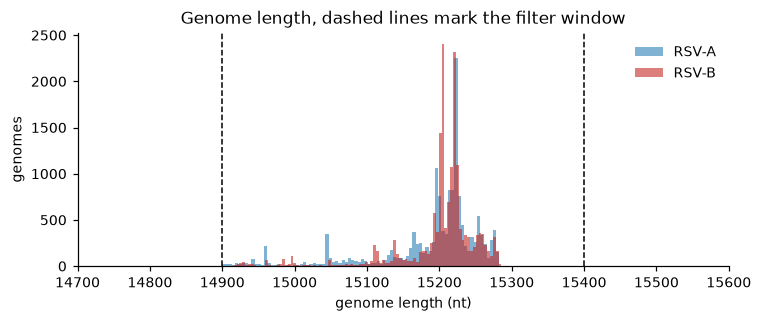

In [3]:
fig, ax = plt.subplots(figsize=(7, 3))
for s in "AB":
    ax.hist(d.loc[d.Subtype == s, "seq_len_actual"], bins=110,
            alpha=.6, label=f"RSV-{s}", color=PAL[s])
for x in (14900, 15400):
    ax.axvline(x, ls="--", lw=1, c="k")
ax.set_xlim(14700, 15600)
ax.set_xlabel("genome length (nt)"); ax.set_ylabel("genomes")
ax.set_title("Genome length, dashed lines mark the filter window")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

## 1.3  When and where the sequences come from

Two features of the sampling matter for everything that follows.

**Sequencing is not evenly spread over time.** It rises steeply from 2018 and dips in 2020–21, when COVID-19 disrupted both RSV circulation and surveillance.

**Sequencing is not evenly spread over the world.** Europe contributes far more genomes than anywhere else.

Any trend measured over calendar time is therefore partly a trend in *who was sequencing*. This is the main reason the analysis in notebook 03 is done inside lineages rather than across the whole dataset.

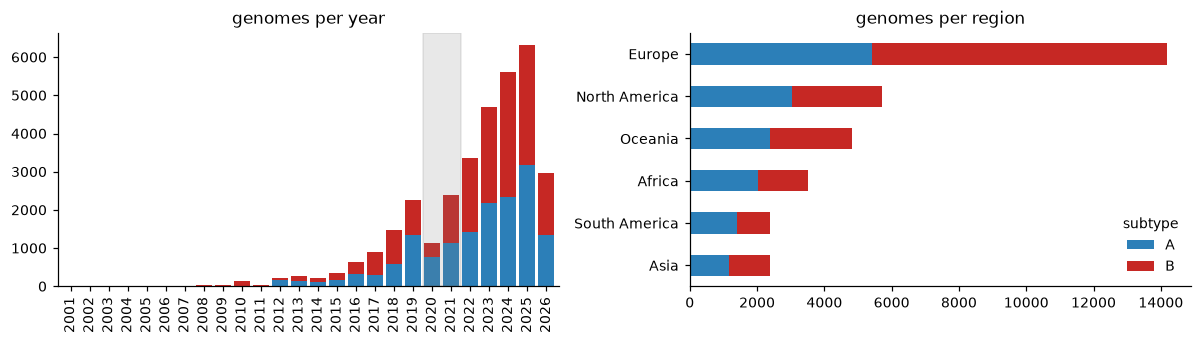

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
yr = d.groupby(["year", "Subtype"]).size().unstack(fill_value=0)
yr.plot.bar(stacked=True, ax=ax[0], color=[PAL["A"], PAL["B"]], width=.85,
            legend=False)
ax[0].set_title("genomes per year"); ax[0].set_xlabel("")
ax[0].axvspan(yr.index.get_loc(2020) - .5, yr.index.get_loc(2021) + .5,
              color="grey", alpha=.18)
reg = d.groupby(["region", "Subtype"]).size().unstack(fill_value=0).sort_values("A")
reg.plot.barh(stacked=True, ax=ax[1], color=[PAL["A"], PAL["B"]])
ax[1].set_title("genomes per region"); ax[1].set_ylabel("")
ax[1].legend(title="subtype", frameon=False)
plt.tight_layout(); plt.show()

*Grey band marks the COVID-19 disruption.*

## 1.4  Known problems with this dataset

Four, found by auditing the data before analysing it. Two of them change what we do.

---

### (a) The 2026 tail is incomplete, so we cut it

The download was made in October 2026, but sequences take months to be deposited. Comparing 2026 month by month against the same months of 2025 separates deposition lag from ordinary seasonality.

In [5]:
m = {y: d[d.date.str.startswith(str(y))].date.str.slice(5, 7).value_counts().sort_index()
     for y in (2025, 2026)}
cmp = pd.DataFrame(m).fillna(0).astype(int)
cmp["2026 as % of 2025"] = (cmp[2026] / cmp[2025] * 100).round(0)
print(cmp.to_string())
print("\nlast collection date:", d.date.max())

      2025  2026  2026 as % of 2025
date                               
01    1094   949               87.0
02     670   583               87.0
03     517   481               93.0
04     386   301               78.0
05     292   268               92.0
06     351   187               53.0
07     519   149               29.0
08     399    18                5.0
09     246    18                7.0
10     324     6                2.0
11     590     0                0.0
12     931     0                0.0

last collection date: 2026-10-16


Through May, 2026 runs at 78-93% of the previous year, which is normal. From June it falls to 53%, July 29%, and August to 5% - eighteen genomes where 2025 had 399 in the same month. That is deposition lag, not season: those months are a non-random subset contributed only by laboratories that deposit quickly.

**Decision: the window runs from 2001 to the end of June 2026.** Everything earlier is kept. Sequencing effort grows steeply over the period, but uneven sample sizes across time do not bias a slope; they only make later years more precisely estimated.

---

### (b) Where sequencing happens has shifted completely

This is the more serious problem.

In [6]:
reg = pd.crosstab(d.year, d.region, normalize="index").mul(100).round(1)
reg.loc[2015:2026]

region,Africa,Asia,Europe,North America,Oceania,South America
year,,,,,,
2015,10.3,1.7,18.1,12.0,38.2,19.8
2016,16.1,5.1,13.7,6.2,47.9,10.9
2017,21.4,6.1,20.7,0.0,44.0,7.8
2018,17.7,14.0,34.3,8.9,15.5,9.6
2019,14.9,13.1,41.8,17.0,7.8,5.4
2020,10.3,11.6,35.4,21.6,20.6,0.5
2021,5.5,9.5,36.7,9.1,36.4,2.7
2022,3.8,4.9,46.8,20.8,21.4,2.3
2023,8.1,6.5,47.4,22.3,11.7,4.0


Oceania supplied 38% of genomes in 2015 and 4% in 2026; Europe went from 18% to 56%. North America contributes nothing at all in 2017.

So **calendar time and geography are entangled**. A composition trend over time could partly be a trend in which part of the world was sequencing.

Worse, this drift happens *inside* individual lineages too, so analysing within lineages does not remove it. Lineage A.D goes from 71% Oceania in its early period to 36% Europe in its late period.

**Decision: region is included as a covariate in the regressions, and results are reported with and without it** (notebook 03).

---

### (c) Strong seasonality — noted, not corrected

RSV is seasonal, so genomes are not spread evenly through the year.

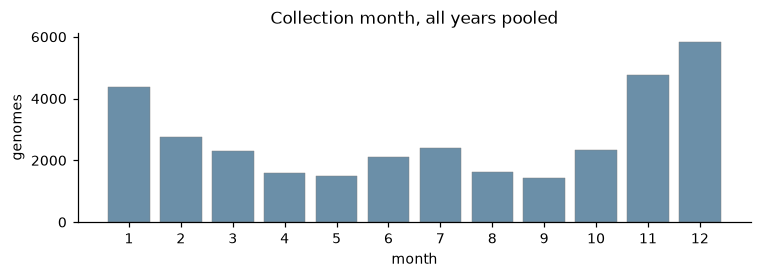

In [7]:
mo = d.date.str.slice(5, 7).value_counts().sort_index()
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.bar(range(1, 13), mo.values, color="#6B8FA8", edgecolor="grey", linewidth=.3)
ax.set_xticks(range(1, 13)); ax.set_xlabel("month"); ax.set_ylabel("genomes")
ax.set_title("Collection month, all years pooled")
plt.tight_layout(); plt.show()

December and November carry three to four times September. Northern and southern hemisphere epidemics also peak at opposite times, so season and geography are partly entangled as well. For a slope measured across a decade this is minor, so we record it rather than correct it.

---

### (d) Early data is sparse, so single genomes could distort a trend

Everything before 2015 is about 3% of the dataset, and **RSV-A has essentially no sequences before 2010**. Keeping it is still worth doing, because for some lineages it adds years of span and a longer span makes a slope more precise.

The danger is leverage. Lineage A.D.3 would otherwise reach back 6.9 extra years on the strength of **one** genome from 2010; a point that isolated drags the fitted line hard. So each lineage is cut back to the run of years in which it was actually being sampled, dropping leading and trailing years holding fewer than 5 genomes. Well-sampled early data survives: lineage A.D keeps 361 genomes in its first three years.

## 1.5  Lineages

GISAID assigns each genome to a **lineage**, a named branch of the RSV family tree. The labels are hierarchical and dot-separated, so `A.D.1.5` sits inside `A.D.1`, which sits inside `A.D`.

Lineages rise and fall over a few seasons. Notebook 03 explains why that matters and how we choose the level to work at.

In [8]:
for s in "AB":
    top = d[d.Subtype == s].Lineage.value_counts().head(5)
    print(f"RSV-{s} most common lineage labels")
    print(top.to_string(), "\n")

RSV-A most common lineage labels
Lineage
A.D.3      2451
A.D.5.2    1523
A.D        1377
A.D.1      1196
A.D.1.5     998 

RSV-B most common lineage labels
Lineage
B.D.E.1      9219
B.D.4.1.1    3237
B.D.E.1.2    1344
B.D.4.1       912
B.D.E.4       717 

